In [64]:
from google.colab import files

uploaded = files.upload()

Saving telco_customer_churn.csv to telco_customer_churn (2).csv


Original Shape: (7043, 21)

--- Unique Values & Most Common ---

Column: customerID
  Unique count: 7043
  Unique values: ['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' '7795-CFOCW' '9237-HQITU']
  Most Common: 0002-ORFBO (Count: 1)

Column: gender
  Unique count: 2
  Unique values: ['Female' 'Male']
  Most Common: Male (Count: 3555)

Column: Partner
  Unique count: 2
  Unique values: ['Yes' 'No']
  Most Common: No (Count: 3641)

Column: Dependents
  Unique count: 2
  Unique values: ['No' 'Yes']
  Most Common: No (Count: 4933)

Column: PhoneService
  Unique count: 2
  Unique values: ['No' 'Yes']
  Most Common: Yes (Count: 6361)

Column: MultipleLines
  Unique count: 3
  Unique values: ['No phone service' 'No' 'Yes']
  Most Common: No (Count: 3390)

Column: InternetService
  Unique count: 3
  Unique values: ['DSL' 'Fiber optic' 'No']
  Most Common: Fiber optic (Count: 3096)

Column: OnlineSecurity
  Unique count: 3
  Unique values: ['No' 'Yes' 'No internet service']
  Most Common: No (Count: 3

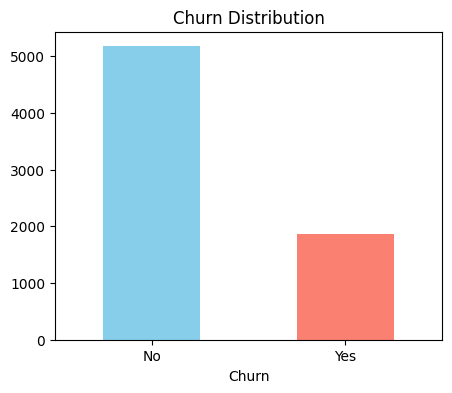


Saved as Cleaned_Telecom_Churn.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [65]:
# DMV EXP 3 - Full with Unique + Most Common + Validation + Download
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

df = pd.read_csv('telco_customer_churn.csv')
print("Original Shape:", df.shape)

# === NEW: Check Unique & Most Common Values ===
print("\n--- Unique Values & Most Common ---")
for col in df.select_dtypes(include=['object']).columns:
    print(f"\nColumn: {col}")
    print(f"  Unique count: {df[col].nunique()}")
    print(f"  Unique values: {df[col].unique()[:5]}") # Show first 5
    print(f"  Most Common: {df[col].mode()[0]} (Count: {df[col].value_counts().iloc[0]})")

# Cleaning
df = df.drop_duplicates()

if 'TotalCharges' in df.columns:
    df['TotalCharges'] = df['TotalCharges'].replace(' ', np.nan)
    df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Handle Missing
for col in df.select_dtypes(include=[np.number]).columns:
    df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(include=['object']).columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

# Outliers
if 'MonthlyCharges' in df.columns:
    Q1 = df['MonthlyCharges'].quantile(0.25)
    Q3 = df['MonthlyCharges'].quantile(0.75)
    IQR = Q3 - Q1
    df = df[(df['MonthlyCharges'] >= Q1-1.5*IQR) & (df['MonthlyCharges'] <= Q3+1.5*IQR)]

# Feature Engineering
if 'TotalCharges' in df.columns and 'tenure' in df.columns:
    df['AvgChargePerTenure'] = df['TotalCharges'] / (df['tenure'] + 1)

print("\n--- After Cleaning ---")
print("Shape:", df.shape)

# === NEW: Data Validation & QA ===
print("\n--- Data Validation & QA ---")
print("1. Missing Values:\n", df.isnull().sum())
print("\n2. Duplicates:", df.duplicated().sum())
print("\n3. Data Types:\n", df.dtypes)
print("\n4. Range Check:")
if 'tenure' in df.columns:
    print(f"   tenure: {df['tenure'].min()} to {df['tenure'].max()} (Should be 0-72)")
if 'MonthlyCharges' in df.columns:
    print(f"   MonthlyCharges: {df['MonthlyCharges'].min()} to {df['MonthlyCharges'].max()}")

# Check for any remaining inconsistent formatting
print("\n5. Final Unique Check for Churn:")
if 'Churn' in df.columns:
    print(df['Churn'].unique())

# Validation Passed?
if df.isnull().sum().sum() == 0 and df.duplicated().sum() == 0:
    print("\n✓ VALIDATION PASSED: No missing, No duplicates, Data is clean!")
else:
    print("\n✗ Validation Failed")

# Visualizations
plt.figure(figsize=(5,4))
if 'Churn' in df.columns:
    df['Churn'].value_counts().plot(kind='bar', color=['skyblue','salmon'])
    plt.title('Churn Distribution')
    plt.xticks(rotation=0)
    plt.show()

# Save & Download
df.to_csv('Cleaned_Telecom_Churn.csv', index=False)
print("\nSaved as Cleaned_Telecom_Churn.csv")
files.download("Cleaned_Telecom_Churn.csv")

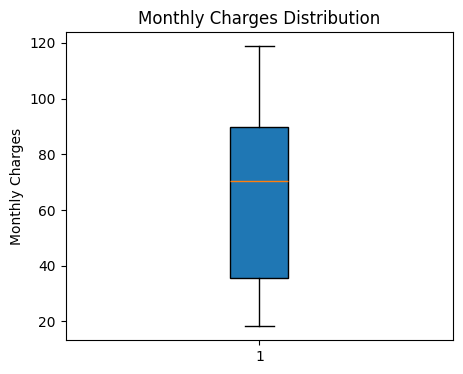

In [66]:
# Graph 2 – Monthly Charges Boxplot

plt.figure(figsize=(5,4))
if 'MonthlyCharges' in df.columns:
    plt.boxplot(df['MonthlyCharges'], patch_artist=True)
    plt.title('Monthly Charges Distribution')
    plt.ylabel('Monthly Charges')
    plt.show()

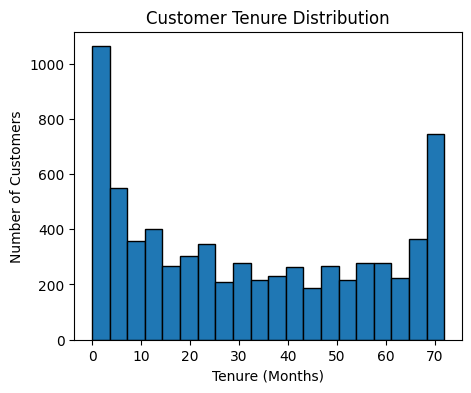

In [67]:
# Graph 3 – Customer Tenure Histogram

plt.figure(figsize=(5,4))
if 'tenure' in df.columns:
    plt.hist(df['tenure'], bins=20, edgecolor='black')
    plt.title('Customer Tenure Distribution')
    plt.xlabel('Tenure (Months)')
    plt.ylabel('Number of Customers')
    plt.show()